# Semana 2 — Slime Mould Algorithm (SMA) aplicado ao Flow Shop

### Implementação, representação de soluções e experimentos iniciais

**Disciplina:** Sistemas Inteligentes  
**Algoritmo:** Slime Mould Algorithm (SMA)  
**Problema:** Permutation Flow Shop Scheduling (PFS)  
**Objetivo:** minimizar o *Total Tardiness* (atraso total).

Este notebook apresenta o funcionamento do SMA e sua aplicação à ordenação de trabalhos em máquinas. A sequência experimental inclui leitura de instâncias, avaliação das soluções, implementação dos operadores, verificações funcionais, visualização da convergência e comparação com busca aleatória. Todas as execuções utilizam sementes definidas e orçamento fixo de avaliações.

## 1. Problema de escalonamento

No **Permutation Flow Shop**, todos os trabalhos percorrem as máquinas na mesma ordem, e a sequência de trabalhos é compartilhada por todas elas. Cada trabalho possui um tempo de processamento em cada máquina e uma data de entrega (*due date*).

Se $\pi$ é a permutação dos trabalhos, o tempo de conclusão do trabalho $\pi_k$ na máquina $i$ é definido por:

$$
C_{i,k}=\max(C_{i-1,k},C_{i,k-1})+p_{\pi_k,i},
$$

com valores iniciais de tempo iguais a zero. O atraso individual e a função objetivo são:

$$
T_j=\max(0,C_{m,j}-d_j),\qquad TT(\pi)=\sum_{j=1}^{n}T_j.
$$

Onde $n$ é o número de trabalhos, $m$ o número de máquinas, $p_{j,i}$ o tempo de processamento, $d_j$ o prazo e $C_{m,j}$ a conclusão na última máquina. **Quanto menor o Total Tardiness, melhor a solução.**

O modelo experimental utiliza uma única linha de produção com $m$ máquinas. A linha do arquivo referente à quantidade de fábricas não participa do cálculo do PFS.

## 2. Ambiente e planejamento experimental

Os arquivos `.txt` do conjunto `DPFSP_DD` são lidos diretamente a partir do diretório de entrada do Kaggle. O caminho é localizado automaticamente; a configuração de execução pode ser modificada na célula abaixo.

| Elemento | Configuração inicial |
|---|---|
| Representação | Random Keys, com uma chave por trabalho |
| Função de avaliação | `FlowShopEngine.evaluate` |
| Objetivo | Total Tardiness |
| População | 30 indivíduos |
| Taxa de reinicialização $z$ | 0,03 |
| Orçamento | 3.000 avaliações por execução |
| Repetições | 5 sementes por método e instância |

`EXECUCAO_COMPLETA = False` permite conferir rapidamente o fluxo experimental com orçamento reduzido, sem alterar a estrutura do notebook.

In [1]:
import time
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

EXECUCAO_COMPLETA = True
SEMENTE_GLOBAL = 2026
np.random.seed(SEMENTE_GLOBAL)
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10,
                     'axes.grid': True, 'grid.alpha': 0.20})

CONFIG = {
    'populacao': 30,
    'z': 0.03,
    'avaliacoes': 3000 if EXECUCAO_COMPLETA else 180,
    'sementes': [11, 22, 33, 44, 55] if EXECUCAO_COMPLETA else [11, 22],
}

PASTAS = [Path('/kaggle/input/datasets/caiomoreiraban/dpfsp-dd/DPFSP_DD'),
          Path('/kaggle/input/dpfsp-dd/DPFSP_DD'),
          Path('/mnt/data/DPFSP_DD')]
DATASET_DIR = next((p for p in PASTAS if (p / 'Small').is_dir() and
                    (p / 'Large').is_dir()), None)
if DATASET_DIR is None and Path('/mnt/data/DPFSP_DD.zip').is_file():
    with zipfile.ZipFile('/mnt/data/DPFSP_DD.zip') as arquivo:
        arquivo.extractall('/mnt/data')
    DATASET_DIR = Path('/mnt/data/DPFSP_DD')
if DATASET_DIR is None and Path('/kaggle/input').exists():
    DATASET_DIR = next((p for p in Path('/kaggle/input').rglob('DPFSP_DD')
                        if (p / 'Small').is_dir() and (p / 'Large').is_dir()), None)
if DATASET_DIR is None:
    raise FileNotFoundError('Anexe o conjunto DPFSP_DD ao Kaggle para executar o notebook.')

ARQUIVOS = sorted(p.relative_to(DATASET_DIR).as_posix()
                  for p in DATASET_DIR.rglob('*.txt'))
def listar_instancias(grupo=None):
    return [s for s in ARQUIVOS if grupo is None or grupo in Path(s).parts]

def carregar_instancia(nome):
    return FlowShopEngine(*FlowShopEngine.carregar_instancia_txt(DATASET_DIR / nome))

OUT = Path('/kaggle/working/semana2_baseline' if Path('/kaggle/working').exists()
           else '/mnt/data/semana2_baseline')
OUT.mkdir(parents=True, exist_ok=True)

print(f'Diretório: {DATASET_DIR}')
print(f'Instâncias encontradas: {len(ARQUIVOS)}')
display(pd.DataFrame([{'Parâmetro': k, 'Valor': str(v)} for k, v in CONFIG.items()]))

Diretório: /kaggle/input/datasets/caiomoreiraban/dpfsp-dd/DPFSP_DD
Instâncias encontradas: 1140


,Parâmetro,Valor
0,populacao,30
1,z,0.03
2,avaliacoes,3000
3,sementes,"[11, 22, 33, 44, 55]"


## 3. Leitura dos dados e avaliação de permutações

A `FlowShopEngine` contém as operações utilizadas para construir os tempos de conclusão e calcular a função objetivo. Cada instância fornece a matriz de tempos de processamento e o vetor de prazos. O método `evaluate` aceita um vetor de chaves contínuas, converte-o em uma sequência e devolve o atraso total.

A avaliação de cada candidato é contabilizada por `cfo_count` (*chamadas à função objetivo*). Esse contador permite manter o mesmo orçamento de busca em todos os métodos.

In [2]:
import numpy as np
import os

class FlowShopEngine:
    def __init__(self, n_jobs, n_machines, proc_times, due_dates):
        """
        Engine unificada para problemas de Flow Shop.
        proc_times: Matriz (n_jobs, n_machines)
        due_dates: Vetor (n_jobs)
        """
        self.n_jobs = n_jobs
        self.n_machines = n_machines
        self.proc_times = proc_times
        self.due_dates = due_dates
        self.cfo_count = 0

    @staticmethod
    def carregar_instancia_txt(caminho_arquivo):
        """Lê N, M, tempos e datas de entrega, no formato TXT disponibilizado."""
        caminho_arquivo = Path(caminho_arquivo)
        if not caminho_arquivo.is_file():
            raise FileNotFoundError(f'Instância não encontrada: {caminho_arquivo}')
        with open(caminho_arquivo, 'r', encoding='utf-8') as f:
            linhas = [linha.strip() for linha in f if linha.strip()]
        num_jobs, num_machines = map(int, linhas[0].split())
        p_matrix = np.zeros((num_jobs, num_machines), dtype=int)
        idx_linha = 2  # A segunda linha indica fábricas; no modo PFS não é utilizada.
        for j in range(num_jobs):
            partes = linhas[idx_linha].split()
            if len(partes) != 2 * num_machines:
                raise ValueError(f'Tempos incompletos para o trabalho {j}')
            for i in range(0, len(partes), 2):
                maq, tempo = int(partes[i]), int(partes[i + 1])
                p_matrix[j, maq] = tempo
            idx_linha += 1
        while idx_linha < len(linhas) and linhas[idx_linha].lower() != 'duedate':
            idx_linha += 1
        if idx_linha >= len(linhas):
            raise ValueError(f'Seção Duedate ausente: {caminho_arquivo}')
        idx_linha += 1
        due_dates = np.array([int(linhas[idx_linha + j]) for j in range(num_jobs)], dtype=int)
        return num_jobs, num_machines, p_matrix, due_dates

    def bucket_sort_decode(self, keys):
        """Converte as chaves contínuas em uma permutação."""
        return np.argsort(keys)

    def evaluate(self, keys, mode="PFS", objective="Tardiness"):
        self.cfo_count += 1
        n, m = self.n_jobs, self.n_machines

        # 1. Decodificação
        if mode == "PFS":
            seq = self.bucket_sort_decode(keys[:n])
            sequences = [seq] * m
        else:
            sequences = []
            for i in range(m):
                sequences.append(self.bucket_sort_decode(keys[i*n : (i+1)*n]))

        # 2. Cálculo das matrizes de tempo (Finish Times)
        # finish_times[i, j] é o tempo de término do job j na máquina i
        finish_times = np.zeros((m, n))

        # Primeira máquina (i=0)
        current_time = 0
        for job_idx in sequences[0]:
            current_time += self.proc_times[job_idx, 0]
            finish_times[0, job_idx] = current_time

        # Máquinas subsequentes (i=1 a m-1)
        for i in range(1, m):
            time_on_m = 0
            for job_idx in sequences[i]:
                # O job precisa terminar na máquina i-1 E a máquina i precisa estar livre
                start = max(time_on_m, finish_times[i-1, job_idx])
                finish_times[i, job_idx] = start + self.proc_times[job_idx, i]
                time_on_m = finish_times[i, job_idx]

        # 3. Retorno do Objetivo
        if objective == "Makespan":
            return np.max(finish_times[m-1, :])

        elif objective == "Tardiness":
            # Total Tardiness = soma de max(0, C_j - d_j)
            tardiness = np.maximum(0, finish_times[m-1, :] - self.due_dates)
            return np.sum(tardiness)

    def evaluate_with_permutation(self, permutation, objective="Tardiness"):
        self.cfo_count += 1
        n, m = self.n_jobs, self.n_machines

        # 1. A permutação já é fornecida, então é usada para todas as máquinas (PFS)
        sequences = [permutation] * m

        # 2. Cálculo das matrizes de tempo (Finish Times)
        # finish_times[i, j] é o tempo de término do job j na máquina i
        finish_times = np.zeros((m, n))

        # Primeira máquina (i=0)
        current_time = 0
        for job_idx in sequences[0]:
            current_time += self.proc_times[job_idx, 0]
            finish_times[0, job_idx] = current_time

        # Máquinas subsequentes (i=1 a m-1)
        for i in range(1, m):
            time_on_m = 0
            for job_idx in sequences[i]:
                # O job precisa terminar na máquina i-1 E a máquina i precisa estar livre
                start = max(time_on_m, finish_times[i-1, job_idx])
                finish_times[i, job_idx] = start + self.proc_times[job_idx, i]
                time_on_m = finish_times[i, job_idx]

        # 3. Retorno do Objetivo
        if objective == "Makespan":
            return np.max(finish_times[m-1, :])

        elif objective == "Tardiness":
            # Total Tardiness = soma de max(0, C_j - d_j)
            tardiness = np.maximum(0, finish_times[m-1, :] - self.due_dates)
            return np.sum(tardiness)

### 3.1. Conhecendo uma instância

Como exemplo, utilizamos `Ta001_2` (20 trabalhos e 5 máquinas). O mapa de calor exibe os tempos de processamento, enquanto o quadro apresenta algumas características da instância. Quanto maior o tempo de processamento ou mais restritivo o prazo, maior pode ser a dificuldade de encontrar uma sequência com atraso reduzido.

Instância: Large/Ta001_2.txt | 20 trabalhos × 5 máquinas


,Trabalho,Prazo,Processamento total
0,1,451,273
1,2,427,289
2,3,238,126
3,4,447,338
4,5,548,353
5,6,285,277
6,7,462,278
7,8,390,221
8,9,324,207
9,10,391,305


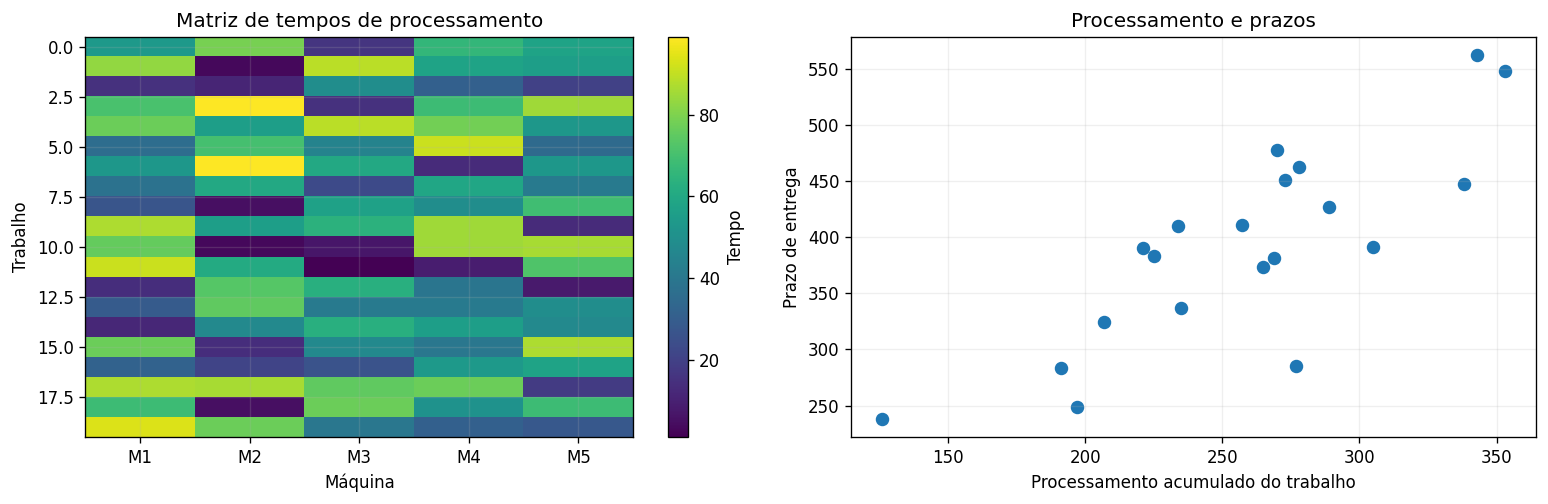

In [3]:
INSTANCIA_DEMONSTRACAO = 'Large/Ta001_2.txt'
eng_demo = carregar_instancia(INSTANCIA_DEMONSTRACAO)

informacoes = pd.DataFrame({
    'Trabalho': np.arange(eng_demo.n_jobs) + 1,
    'Prazo': eng_demo.due_dates,
    'Processamento total': eng_demo.proc_times.sum(axis=1),
})
print(f'Instância: {INSTANCIA_DEMONSTRACAO} | '
      f'{eng_demo.n_jobs} trabalhos × {eng_demo.n_machines} máquinas')
display(informacoes.head(10))

fig, axs = plt.subplots(1, 2, figsize=(13, 4.3))
img = axs[0].imshow(eng_demo.proc_times, aspect='auto', cmap='viridis')
axs[0].set(xlabel='Máquina', ylabel='Trabalho',
           title='Matriz de tempos de processamento')
axs[0].set_xticks(range(eng_demo.n_machines),
                  [f'M{i+1}' for i in range(eng_demo.n_machines)])
fig.colorbar(img, ax=axs[0], label='Tempo')
axs[1].scatter(informacoes['Processamento total'], informacoes['Prazo'], s=50)
axs[1].set(xlabel='Processamento acumulado do trabalho',
           ylabel='Prazo de entrega', title='Processamento e prazos')
plt.tight_layout()
plt.show()

## 4. Representação das soluções com Random Keys

O SMA movimenta vetores contínuos, enquanto o PFS necessita de uma sequência de trabalhos. A representação por **Random Keys** associa uma chave real a cada trabalho e ordena os índices em ordem crescente:

$$\pi=\operatorname{argsort}(X).$$

Por exemplo, se o trabalho 2 receber a menor chave, será processado primeiro. Assim, o algoritmo modifica as chaves, e a função de avaliação recebe a permutação correspondente. Os índices das matrizes começam em zero; nas tabelas e nos gráficos, os trabalhos são numerados a partir de 1 para facilitar a leitura.

,Trabalho,Chave,Posição na sequência
0,2,0.13,1
1,5,0.30,2
2,4,0.45,3
3,1,0.72,4
4,3,0.91,5


Sequência de trabalhos: [2, 5, 4, 1, 3]


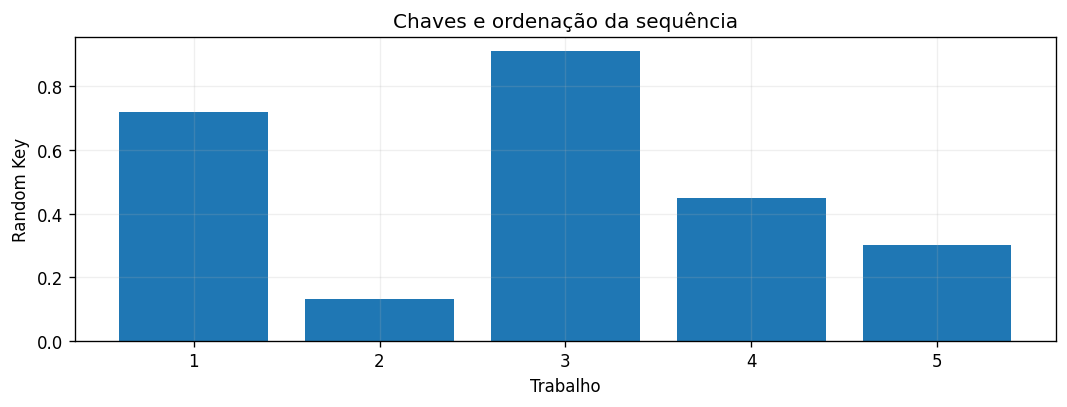

Total Tardiness de uma sequência inicial aleatória: 11221.0


In [4]:
chaves = np.array([0.72, 0.13, 0.91, 0.45, 0.30])
permutacao = np.argsort(chaves)
exemplo = pd.DataFrame({'Trabalho': np.arange(1, len(chaves)+1),
                        'Chave': chaves,
                        'Posição na sequência': np.argsort(np.argsort(chaves)) + 1})
display(exemplo.sort_values('Chave').reset_index(drop=True))
print('Sequência de trabalhos:', (permutacao + 1).tolist())

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(exemplo['Trabalho'], exemplo['Chave'])
ax.set(xlabel='Trabalho', ylabel='Random Key', title='Chaves e ordenação da sequência')
ax.set_xticks(exemplo['Trabalho'])
plt.tight_layout()
plt.show()

rng_demo = np.random.default_rng(13)
chaves_20 = rng_demo.random(eng_demo.n_jobs)
print('Total Tardiness de uma sequência inicial aleatória:',
      float(eng_demo.evaluate(chaves_20, mode='PFS', objective='Tardiness')))

## 5. Slime Mould Algorithm: mecanismos de busca

O **Slime Mould Algorithm (SMA)** é uma meta-heurística populacional inspirada no comportamento de organismos do grupo dos mixomicetos. Cada indivíduo representa uma posição no espaço de busca. Ao longo das gerações, o algoritmo combina informações sobre a qualidade das soluções e movimentos estocásticos.

O procedimento utiliza os seguintes mecanismos:

1. **Avaliação e ranking:** calcula o fitness dos indivíduos e organiza a população do menor para o maior atraso.
2. **Pesos adaptativos $W$:** variam segundo a posição de cada indivíduo no ranking e a diferença entre fitness.
3. **Seleção de movimento:** o parâmetro $p_i=\tanh(|f_i-f_{\mathrm{melhor}}|)$ controla a escolha entre os dois operadores de atualização.
4. **Oscilação e contração:** os coeficientes $v_b$ e $v_c$ determinam os movimentos ao longo das dimensões.
5. **Reinicialização:** com probabilidade $z$, uma posição é reinicializada para ampliar a exploração.

Na implementação, os limites das posições são $[0,1]$. O resultado da otimização é sempre uma permutação obtida da melhor posição contínua. O algoritmo mantém o melhor fitness global, mesmo quando uma nova geração não apresenta melhoria.

**Pesos de cada componente:** para indivíduos ordenados pelo fitness, utiliza-se a razão

$$R_i=\frac{f_{\mathrm{melhor}}-f_i}{f_{\mathrm{melhor}}-f_{\mathrm{pior}}},$$

com $R_i=0$ quando os fitness são iguais. O peso é $1+r\log_{10}(1+R_i)$ na primeira metade da população e $1-r\log_{10}(1+R_i)$ na segunda, com $r\sim U(0,1)$.

**Movimentos por componente:**

$$
X_{i,j}^{t+1}=\begin{cases}
X_{\mathrm{melhor},j}^{t}+v_{b,j}(W_{i,j}X_{A,j}^{t}-X_{B,j}^{t}), & r<p_i,\\
v_{c,j}X_{i,j}^{t}, & r\ge p_i.
\end{cases}
$$

Os coeficientes $v_b$ e $v_c$ são amostrados em intervalos que diminuem ao longo das gerações, enquanto $A$ e $B$ são indivíduos sorteados independentemente para cada componente.

In [5]:
def sma_otimizar(fo, dimensao, populacao=30, avaliacoes=3000, z=0.03, seed=42):
    """Minimiza uma função objetivo com SMA e retorna métricas da execução.

    Parâmetros
    ----------
    fo : callable
        Recebe um vetor de chaves e devolve um fitness escalar.
    dimensao : int
        Número de componentes da posição (trabalhos no PFS).
    populacao : int
        Número de indivíduos.
    avaliacoes : int
        Quantidade máxima de chamadas à função objetivo.
    z : float
        Probabilidade de reinicialização.
    seed : int
        Semente do gerador aleatório.
    """
    n, dim = int(populacao), int(dimensao)
    budget = int(avaliacoes)
    if n < 3 or dim < 1 or budget < n or not (0 <= z <= 1):
        raise ValueError('Parâmetros inválidos para a execução do SMA.')

    rng = np.random.default_rng(seed)
    X = rng.uniform(0.0, 1.0, (n, dim))
    melhor_x = np.zeros(dim)
    melhor_y = float('inf')
    geracoes = int(np.ceil(budget / n))
    total_avaliacoes = 0
    reinicializacoes = 0
    trajetoria = []

    for t in range(1, geracoes + 1):
        # As posições são limitadas antes da avaliação dos indivíduos.
        np.clip(X, 0.0, 1.0, out=X)
        empates = float(np.mean([dim - len(np.unique(row)) for row in X]))

        restantes = budget - total_avaliacoes
        n_avaliados = min(n, restantes)
        fitness = np.full(n, np.inf, dtype=float)
        for i in range(n_avaliados):
            fitness[i] = float(fo(X[i]))
            total_avaliacoes += 1
            if not np.isfinite(fitness[i]):
                raise ValueError('A função objetivo retornou fitness não finito.')
            if fitness[i] < melhor_y:
                melhor_y = fitness[i]
                melhor_x = X[i].copy()

        trajetoria.append({
            'geracao': t,
            'avaliacoes': total_avaliacoes,
            'melhor_fitness': melhor_y,
            'empates_medio': empates,
        })
        if total_avaliacoes == budget:
            break

        ordem = np.argsort(fitness, kind='stable')
        melhor_atual = float(fitness[ordem[0]])
        pior_atual = float(fitness[ordem[-1]])
        W = np.ones_like(X)
        denom = melhor_atual - pior_atual
        for pos, i in enumerate(ordem):
            razao = (melhor_atual - fitness[i]) / denom if denom != 0 else 0.0
            sinal = 1.0 if pos + 1 <= n / 2 else -1.0
            termo = np.log10(1.0 + razao)
            for j in range(dim):
                W[i, j] = 1.0 + sinal * rng.random() * termo

        # Os coeficientes de movimento diminuem ao longo da execução.
        a = float(np.arctanh(1.0 - t / geracoes))
        b = float(1.0 - t / geracoes)
        for i in range(n):
            if rng.random() < z:
                X[i, :] = rng.random()
                reinicializacoes += 1
            else:
                p = float(np.tanh(abs(fitness[i] - melhor_y)))
                vb = rng.uniform(-a, a, size=dim)
                vc = rng.uniform(-b, b, size=dim)
                for j in range(dim):
                    r = rng.random()
                    A = int(rng.integers(0, n))
                    B = int(rng.integers(0, n))
                    if r < p:
                        X[i, j] = melhor_x[j] + vb[j] * (W[i, j] * X[A, j] - X[B, j])
                    else:
                        X[i, j] = vc[j] * X[i, j]

    historico = pd.DataFrame(trajetoria)
    return {
        'fitness': float(melhor_y),
        'melhor_posicao': melhor_x,
        'melhor_permutacao': np.argsort(melhor_x),
        'cfo': total_avaliacoes,
        'historico': historico,
        'reinicializacoes': reinicializacoes,
        'empates_medio': float(historico['empates_medio'].mean()),
    }

### 5.1. Testes de funcionamento

Os testes verificam o cálculo da função objetivo em um exemplo conhecido, a correspondência entre a avaliação por chaves e por permutação, o respeito ao orçamento, a validade da sequência e a preservação do melhor fitness histórico. São testes de integridade da implementação; o desempenho de otimização será examinado nas seções experimentais.

In [6]:
def executar_testes():
    # Duas sequências de um problema PFS com dois trabalhos e duas máquinas.
    mini = FlowShopEngine(2, 2, np.array([[2, 3], [4, 1]]), np.array([3, 7]))
    assert mini.evaluate_with_permutation(np.array([0, 1])) == 2
    assert mini.evaluate_with_permutation(np.array([1, 0])) == 6

    e = carregar_instancia(listar_instancias('Small')[0])
    keys = np.random.default_rng(202).random(e.n_jobs)
    f_keys = e.evaluate(keys, mode='PFS', objective='Tardiness')
    f_perm = e.evaluate_with_permutation(np.argsort(keys), objective='Tardiness')
    assert f_keys == f_perm

    contador = [0]
    def sphere(x):
        contador[0] += 1
        return float(np.sum((np.asarray(x) - 0.25) ** 2))
    r = sma_otimizar(sphere, dimensao=6, populacao=10,
                     avaliacoes=100, z=0.03, seed=17)
    assert contador[0] == r['cfo'] == 100
    assert len(np.unique(r['melhor_permutacao'])) == 6
    assert np.all(np.diff(r['historico']['melhor_fitness']) <= 1e-12)
    assert np.all((r['melhor_posicao'] >= 0) & (r['melhor_posicao'] <= 1))
    assert np.isfinite(r['fitness'])
    print('Testes funcionais concluídos com sucesso.')
    print('Sphere (teste de integridade):', round(r['fitness'], 6))
    print('Engine: avaliação por chaves e por permutação consistente.')

executar_testes()

Testes funcionais concluídos com sucesso.
Sphere (teste de integridade): 0.041356
Engine: avaliação por chaves e por permutação consistente.


## 6. Execução do SMA em uma instância de Flow Shop

Nesta execução, o SMA procura uma sequência de trabalhos com atraso total reduzido. A curva apresenta o melhor fitness conhecido após cada lote de avaliações. Como a função objetivo é minimizada, os trechos descendentes representam descobertas de soluções melhores; patamares indicam períodos sem melhoria global.

Melhor Total Tardiness: 7,142
Sequência de trabalhos: [3, 15, 17, 13, 14, 8, 16, 11, 1, 2, 7, 10, 12, 9, 6, 19, 5, 18, 20, 4]
Avaliações: 3000 | Tempo: 0.711 s
Empates médios nas chaves por indivíduo: 3.22


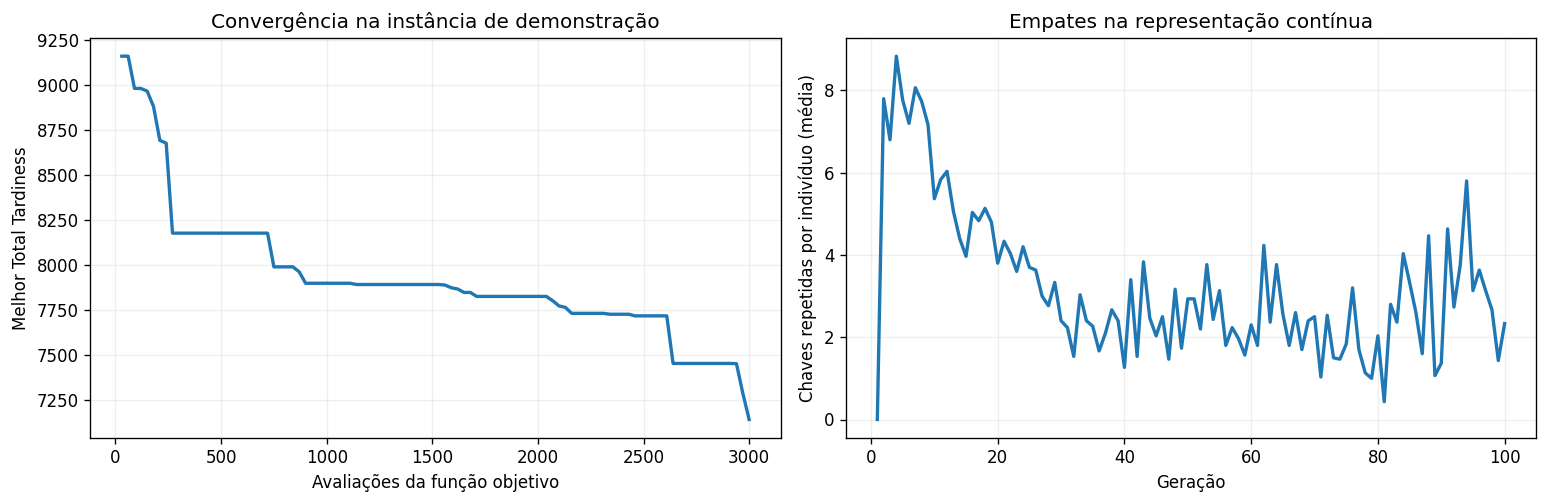

In [7]:
eng = carregar_instancia(INSTANCIA_DEMONSTRACAO)
eng.cfo_count = 0
inicio = time.perf_counter()
resultado_demo = sma_otimizar(lambda x: eng.evaluate(x, mode='PFS', objective='Tardiness'),
                             dimensao=eng.n_jobs, populacao=CONFIG['populacao'],
                             avaliacoes=CONFIG['avaliacoes'], z=CONFIG['z'], seed=11)
duracao = time.perf_counter() - inicio
assert resultado_demo['cfo'] == eng.cfo_count == CONFIG['avaliacoes']

print(f'Melhor Total Tardiness: {resultado_demo["fitness"]:,.0f}')
print('Sequência de trabalhos:', (resultado_demo['melhor_permutacao'] + 1).tolist())
print(f'Avaliações: {resultado_demo["cfo"]} | Tempo: {duracao:.3f} s')
print(f'Empates médios nas chaves por indivíduo: {resultado_demo["empates_medio"]:.2f}')

fig, axs = plt.subplots(1, 2, figsize=(13, 4.3))
hist = resultado_demo['historico']
axs[0].plot(hist['avaliacoes'], hist['melhor_fitness'], linewidth=2)
axs[0].set(xlabel='Avaliações da função objetivo', ylabel='Melhor Total Tardiness',
           title='Convergência na instância de demonstração')
axs[1].plot(hist['geracao'], hist['empates_medio'], linewidth=2)
axs[1].set(xlabel='Geração', ylabel='Chaves repetidas por indivíduo (média)',
           title='Empates na representação contínua')
plt.tight_layout()
plt.show()

## 7. Experimento em múltiplas instâncias

Para avaliar a qualidade inicial do SMA, executamos o algoritmo em três instâncias Small e em duas instâncias Large, utilizando cinco sementes. Como referência de desempenho, uma **busca aleatória** gera vetores de chaves independentes e registra o melhor atraso obtido. Ambos os procedimentos possuem o mesmo orçamento de avaliações e são executados sobre as mesmas instâncias.

A média resume a qualidade típica das soluções, enquanto o desvio-padrão mostra a variabilidade entre execuções. Comparações de atraso devem ser feitas **dentro da mesma instância**, pois os valores absolutos diferem conforme o tamanho do problema.

In [8]:
instancias = listar_instancias('Small')[:3]
instancias += [s for s in ['Large/Ta001_2.txt', 'Large/Ta041_3.txt'] if s in ARQUIVOS]
if not instancias:
    raise RuntimeError('Nenhuma instância disponível para o experimento.')

registros = []
curvas = {}
for nome in instancias:
    for semente in CONFIG['sementes']:
        for metodo in ['SMA', 'Busca aleatória']:
            e = carregar_instancia(nome)
            e.cfo_count = 0
            ini = time.perf_counter()
            if metodo == 'SMA':
                r = sma_otimizar(lambda keys: e.evaluate(keys, mode='PFS', objective='Tardiness'),
                                 dimensao=e.n_jobs, populacao=CONFIG['populacao'],
                                 avaliacoes=CONFIG['avaliacoes'], z=CONFIG['z'], seed=semente)
                fitness = r['fitness']
                empates = r['empates_medio']
                curvas[(nome, semente)] = r['historico']
            else:
                rng = np.random.default_rng(semente)
                fitness = float('inf')
                for _ in range(CONFIG['avaliacoes']):
                    fitness = min(fitness, float(e.evaluate(rng.random(e.n_jobs),
                                                           mode='PFS', objective='Tardiness')))
                empates = np.nan
            tempo = time.perf_counter() - ini
            assert e.cfo_count == CONFIG['avaliacoes']
            registros.append({'instancia': nome, 'metodo': metodo,
                              'semente': semente, 'total_tardiness': fitness,
                              'tempo_s': tempo, 'empates_medio': empates})

EXECUCOES = pd.DataFrame(registros)
RESUMO = EXECUCOES.groupby(['instancia', 'metodo'], as_index=False).agg(
    media=('total_tardiness', 'mean'),
    desvio=('total_tardiness', 'std'),
    melhor=('total_tardiness', 'min'),
    pior=('total_tardiness', 'max'),
    tempo_medio_s=('tempo_s', 'mean'))
print('Execuções realizadas:', len(EXECUCOES))
display(RESUMO.round(3))

Execuções realizadas: 50


,instancia,metodo,media,desvio,melhor,pior,tempo_medio_s
0,Large/Ta001_2.txt,Busca aleatória,8013.8,103.468,7921.0,8187.0,0.299
1,Large/Ta001_2.txt,SMA,6956.0,261.916,6640.0,7298.0,0.700
2,Large/Ta041_3.txt,Busca aleatória,59192.8,573.346,58678.0,60064.0,1.463
3,Large/Ta041_3.txt,SMA,52921.8,1267.749,51164.0,54331.0,2.379
4,Small/I_2_10_2_1.txt,Busca aleatória,2490.8,18.620,2467.0,2519.0,0.096
5,Small/I_2_10_2_1.txt,SMA,2438.0,0.000,2438.0,2438.0,0.317
6,Small/I_2_10_2_2.txt,Busca aleatória,1928.6,26.121,1885.0,1950.0,0.099
7,Small/I_2_10_2_2.txt,SMA,1836.0,8.944,1832.0,1852.0,0.326
8,Small/I_2_10_2_3.txt,Busca aleatória,2419.6,21.755,2396.0,2453.0,0.096
9,Small/I_2_10_2_3.txt,SMA,2357.4,3.130,2356.0,2363.0,0.326


## 8. Visualização e interpretação dos resultados

A figura à esquerda apresenta o Total Tardiness médio por instância. A figura à direita mostra as curvas de convergência das diferentes sementes em uma instância Large. Os gráficos permitem identificar diferenças de qualidade e a estabilidade do processo de busca.

Como o SMA é estocástico, resultados individuais não devem ser tratados como desempenho garantido. Para estudos conclusivos, é recomendável ampliar as repetições e utilizar testes estatísticos apropriados.

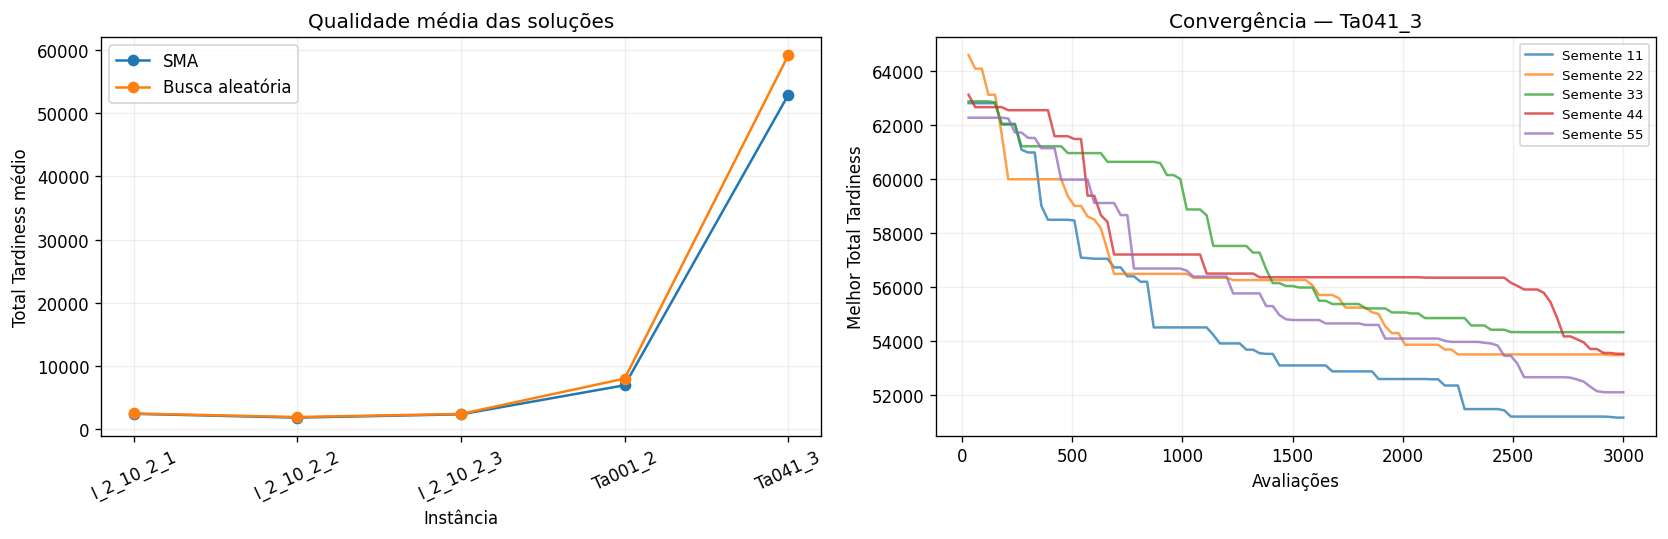

Ganho relativo do SMA sobre a busca aleatória (positivo = menor atraso):


metodo,SMA,Busca aleatória,ganho_SMA_%
instancia,,,
Large/Ta001_2.txt,6956.0,8013.8,13.20
Large/Ta041_3.txt,52921.8,59192.8,10.59
Small/I_2_10_2_1.txt,2438.0,2490.8,2.12
Small/I_2_10_2_2.txt,1836.0,1928.6,4.80
Small/I_2_10_2_3.txt,2357.4,2419.6,2.57


In [9]:
nomes = [Path(s).stem for s in instancias]
fig, axs = plt.subplots(1, 2, figsize=(14, 4.6))
for metodo in ['SMA', 'Busca aleatória']:
    dados = RESUMO[RESUMO['metodo'] == metodo].set_index('instancia').loc[instancias]
    axs[0].plot(nomes, dados['media'].to_numpy(), marker='o', label=metodo)
axs[0].set(xlabel='Instância', ylabel='Total Tardiness médio',
           title='Qualidade média das soluções')
axs[0].tick_params(axis='x', labelrotation=25)
axs[0].legend()

instancia_curva = instancias[-1]
for semente in CONFIG['sementes']:
    dados = curvas[(instancia_curva, semente)]
    axs[1].plot(dados['avaliacoes'], dados['melhor_fitness'],
                alpha=0.75, label=f'Semente {semente}')
axs[1].set(xlabel='Avaliações', ylabel='Melhor Total Tardiness',
           title=f'Convergência — {Path(instancia_curva).stem}')
axs[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

pivot = RESUMO.pivot(index='instancia', columns='metodo', values='media')
pivot['ganho_SMA_%'] = 100 * (pivot['Busca aleatória'] - pivot['SMA']) / pivot['Busca aleatória']
print('Ganho relativo do SMA sobre a busca aleatória (positivo = menor atraso):')
display(pivot[['SMA', 'Busca aleatória', 'ganho_SMA_%']].round(2))

## 9. Discussão dos resultados

As métricas e figuras permitem avaliar a execução inicial do SMA no PFS. A principal medida de qualidade é o **Total Tardiness**, acompanhado por dispersão entre sementes e custo computacional.

Pontos considerados na análise:

- **Qualidade da solução:** comparar médias e melhores valores obtidos em cada instância.
- **Consistência:** examinar o desvio-padrão e a variação das curvas entre sementes.
- **Progresso da busca:** verificar se novas avaliações continuam reduzindo o melhor atraso.
- **Representação:** acompanhar a incidência de chaves empatadas, que podem influenciar a conversão em permutações.
- **Custo computacional:** distinguir quantidade de avaliações e tempo total de execução.

O experimento fornece uma caracterização inicial da busca; a seleção sistemática de hiperparâmetros pode ser estudada separadamente.

In [10]:
print('SÍNTESE DO EXPERIMENTO')
for nome in instancias:
    tab = RESUMO[RESUMO.instancia == nome].set_index('metodo')
    sma = tab.loc['SMA']
    random = tab.loc['Busca aleatória']
    ganho = 100 * (random['media'] - sma['media']) / random['media']
    print(f'{Path(nome).stem}: SMA={sma["media"]:.1f} ± {sma["desvio"]:.1f}; '
          f'aleatória={random["media"]:.1f}; ganho={ganho:+.2f}%')

SÍNTESE DO EXPERIMENTO
I_2_10_2_1: SMA=2438.0 ± 0.0; aleatória=2490.8; ganho=+2.12%
I_2_10_2_2: SMA=1836.0 ± 8.9; aleatória=1928.6; ganho=+4.80%
I_2_10_2_3: SMA=2357.4 ± 3.1; aleatória=2419.6; ganho=+2.57%
Ta001_2: SMA=6956.0 ± 261.9; aleatória=8013.8; ganho=+13.20%
Ta041_3: SMA=52921.8 ± 1267.7; aleatória=59192.8; ganho=+10.59%


## 10. Reprodutibilidade e arquivos gerados

Os resultados são exportados como arquivos CSV, incluindo a identificação da instância, do método, da semente e do orçamento utilizado. O notebook também preserva a configuração experimental na pasta de saída.

**Referência bibliográfica:** Li, S., Chen, H., Wang, M., Heidari, A. A. e Mirjalili, S. (2020). *Slime mould algorithm: A new method for stochastic optimization*. Future Generation Computer Systems. https://doi.org/10.1016/j.future.2020.03.055

In [11]:
EXECUCOES.to_csv(OUT / 'execucoes_baseline.csv', index=False)
RESUMO.to_csv(OUT / 'resumo_baseline.csv', index=False)
(OUT / 'configuracao_baseline.json').write_text(
    __import__('json').dumps({**CONFIG, 'instancias': instancias,
                              'dataset': str(DATASET_DIR),
                              'objetivo': 'Total Tardiness',
                              'modo': 'PFS'}, indent=2, ensure_ascii=False),
    encoding='utf-8')
print('Arquivos exportados em:', OUT)
for arquivo in sorted(OUT.iterdir()):
    if arquivo.name in ['execucoes_baseline.csv', 'resumo_baseline.csv',
                        'configuracao_baseline.json']:
        print(' -', arquivo.name)

Arquivos exportados em: /kaggle/working/semana2_baseline
 - configuracao_baseline.json
 - execucoes_baseline.csv
 - resumo_baseline.csv
